#chapter1
import dati e calcolo curva dei rendimenti

In [2]:
import csv
import numpy as np
import pandas as pd

DataFolder = "ItalyBondData"

def load_csv(filename):
    path = f"{DataFolder}/{filename}"
    df = pd.read_csv(path)
    # One yield CSV is exported with each complete row quoted as a single field.
    if "Date" not in df.columns and len(df.columns) == 1:
        df = pd.read_csv(path, quoting=csv.QUOTE_NONE)
        df.columns = df.columns.str.replace('\"', "", regex=False)
        df = df.apply(lambda column: column.str.replace('\"', "", regex=False))
    # Investing usa formato data MM/DD/YYYY e num. con eventuale '%'
    dates = pd.to_datetime(df["Date"], format="%m/%d/%Y")
    values = pd.to_numeric(df["Price"].astype(str).str.replace("%", ""), errors="coerce")
    return pd.Series(values.values, index=dates).dropna().sort_index()

# 1. DataFrame dei rendimenti (8 nodi in anni)
tenors = np.array([0.25, 0.50, 1.0, 2.0, 5.0, 7.0, 10.0, 20.0])
yield_filenames = [
    "Italy 3-Month Bond Yield Historical Data.csv",
    "Italy 6-Month Bond Yield Historical Data.csv",
    "Italy 1-Year Bond Yield Historical Data.csv",
    "BTP 2 anni Dati Storici Rendimento Bond.csv",
    "Italy 5-Year Bond Yield Historical Data.csv",
    "BTP 7 anni Dati Storici Rendimento Bond.csv",
    "BTP 10 anni Dati Storici Rendimento Bond.csv",
    "Italy 20-Year Bond Yield Historical Data.csv",
]

df_yields = pd.DataFrame({tau: load_csv(fn) / 100.0 for tau, fn in zip(tenors, yield_filenames)}).dropna()

# 2. DataFrame dei prezzi dei 5 BTP
btp_files = {
    "BTP_2028": "IT000534092 Overview.csv",
    "BTP_2031": "IT000543669 Overview.csv",
    "BTP_2036": "IT000540211 Overview.csv",
    "BTP_2039": "IT000558242 Overview.csv",
    "BTP_2047": "IT000516282 Overview.csv",
}

df_prices = pd.DataFrame({name: load_csv(fn) for name, fn in btp_files.items()}).dropna()

# Intersezione delle date comuni tra rendimenti e prezzi
common_dates = df_yields.index.intersection(df_prices.index)
df_yields = df_yields.loc[common_dates]
df_prices = df_prices.loc[common_dates]

# Estraiamo i dati di OGGI (ultima riga) in NumPy per iniziare
today = common_dates[-1]
y_today = df_yields.iloc[-1].to_numpy()   # 8 rendimenti di oggi (in decimali)
p_today = df_prices.iloc[-1].to_numpy()   # 5 prezzi Clean di oggi

print(f"Data di riferimento (oggi): {today.date()} (su {len(common_dates)} giorni totali)") #forse per qualcuno non ho preso tutta la serie storicca dal 2024, da ricontrollare
print("Rendimenti oggi (%):", np.round(y_today * 100, 3))
print("Prezzi BTP oggi:    ", np.round(p_today, 3))

ValueError: time data "3" doesn't match format "%m/%d/%Y". You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

Parametri Nelson-Siegel: beta0=0.0516, beta1=-0.0243, beta2=0.0000, lambda=3.171 | RMSE = 8.08 bps
Parametri Svensson:      beta0=0.0540, beta1=-0.0288, beta2=0.3872, beta3=-0.3979, lam1=1.947, lam2=2.033 | RMSE = 2.65 bps
Parametri NS Lineare (lambda=1.37): beta0=0.0490, beta1=-0.0219, beta2=-0.0125 | RMSE = 10.74 bps


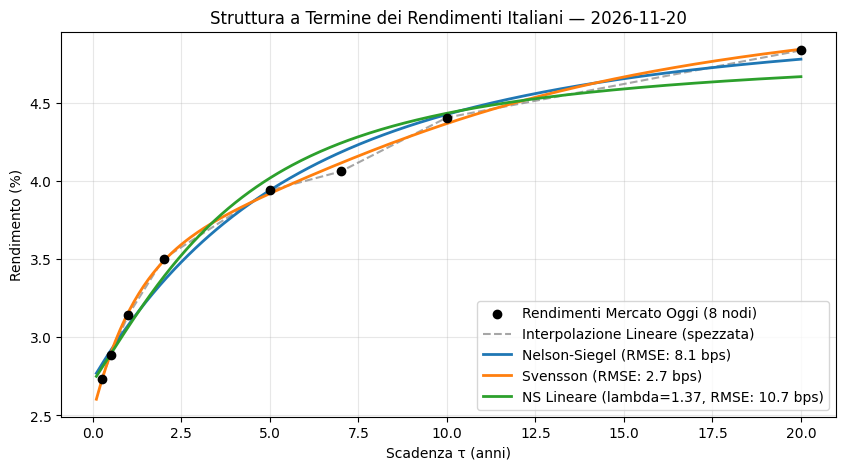

In [ ]:
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

# 1. Definizione analitica di Nelson-Siegel e Svensson
def nelson_siegel(tau, beta0, beta1, beta2, lam):
    x = tau / lam
    factor1 = (1.0 - np.exp(-x)) / x
    factor2 = factor1 - np.exp(-x)
    return beta0 + beta1 * factor1 + beta2 * factor2

def svensson(tau, beta0, beta1, beta2, beta3, lam1, lam2):
    x2 = tau / lam2
    factor3 = (1.0 - np.exp(-x2)) / x2 - np.exp(-x2)
    return nelson_siegel(tau, beta0, beta1, beta2, lam1) + beta3 * factor3

# 2. Stima ai Minimi Quadrati Non Lineari (NLS) su y_today
res_ns = least_squares(
    lambda p: nelson_siegel(tenors, *p) - y_today,
    x0=[0.05, -0.02, 0.01, 2.0],
    bounds=([0.0, -0.5, -0.5, 0.05], [0.5, 0.5, 0.5, 30.0])
)
params_ns = res_ns.x

res_nss = least_squares(
    lambda p: svensson(tenors, *p) - y_today,
    x0=[0.05, -0.02, 0.01, -0.01, 1.5, 6.0],
    bounds=([0.0, -0.5, -0.5, -0.5, 0.05, 0.05], [0.5, 0.5, 0.5, 0.5, 30.0, 30.0])
)
params_nss = res_nss.x

# Errore quadratico medio (RMSE in basis points, 1% = 100 bps)
rmse_ns = np.sqrt(np.mean(res_ns.fun**2)) * 10000
rmse_nss = np.sqrt(np.mean(res_nss.fun**2)) * 10000

# Nelson-Siegel Lineare (OLS con lambda fisso = 1.37, stile Diebold-Li / Banche Centrali)
lam_fixed = 1.37
x_fixed = tenors / lam_fixed
L1 = (1.0 - np.exp(-x_fixed)) / x_fixed
L2 = L1 - np.exp(-x_fixed)
X_ols = np.column_stack([np.ones_like(tenors), L1, L2])  # Matrice 8x3

beta_ols, _, _, _ = np.linalg.lstsq(X_ols, y_today, rcond=None)
rmse_ols = np.sqrt(np.mean((X_ols @ beta_ols - y_today)**2)) * 10000


print(f"Parametri Nelson-Siegel: beta0={params_ns[0]:.4f}, beta1={params_ns[1]:.4f}, beta2={params_ns[2]:.4f}, lambda={params_ns[3]:.3f} | RMSE = {rmse_ns:.2f} bps")
print(f"Parametri Svensson:      beta0={params_nss[0]:.4f}, beta1={params_nss[1]:.4f}, beta2={params_nss[2]:.4f}, beta3={params_nss[3]:.4f}, lam1={params_nss[4]:.3f}, lam2={params_nss[5]:.3f} | RMSE = {rmse_nss:.2f} bps")
print(f"Parametri NS Lineare (lambda=1.37): beta0={beta_ols[0]:.4f}, beta1={beta_ols[1]:.4f}, beta2={beta_ols[2]:.4f} | RMSE = {rmse_ols:.2f} bps")

# 3. Grafico di confronto
tau_grid = np.linspace(0.1, 20.0, 300)
plt.figure(figsize=(10, 5))
plt.scatter(tenors, y_today * 100, color="black", zorder=5, label="Rendimenti Mercato Oggi (8 nodi)")
plt.plot(tenors, y_today * 100, "--", color="gray", alpha=0.7, label="Interpolazione Lineare (spezzata)")
plt.plot(tau_grid, nelson_siegel(tau_grid, *params_ns) * 100, linewidth=2, label=f"Nelson-Siegel (RMSE: {rmse_ns:.1f} bps)")
plt.plot(tau_grid, svensson(tau_grid, *params_nss) * 100, linewidth=2, label=f"Svensson (RMSE: {rmse_nss:.1f} bps)")
plt.plot(
    tau_grid,
    nelson_siegel(tau_grid, *beta_ols, lam_fixed) * 100,
    linewidth=2,
    label=f"NS Lineare (lambda={lam_fixed:.2f}, RMSE: {rmse_ols:.1f} bps)"
)

plt.title(f"Struttura a Termine dei Rendimenti Italiani — {today.date()}")
plt.xlabel("Scadenza τ (anni)")
plt.ylabel("Rendimento (%)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()



In [ ]:
from scipy.optimize import brentq
today = df_yields.index[-1]
btp_specs = [
    {"name": "BTP_2028", "maturity": "2028-12-01", "coupon": 0.0280, "freq": 2},
    {"name": "BTP_2031", "maturity": "2031-08-01", "coupon": 0.0060, "freq": 2},
    {"name": "BTP_2036", "maturity": "2036-03-01", "coupon": 0.0145, "freq": 2},
    {"name": "BTP_2039", "maturity": "2039-10-01", "coupon": 0.0415, "freq": 2},
    {"name": "BTP_2047", "maturity": "2047-03-01", "coupon": 0.0270, "freq": 2},
]

def get_cashflows(val_date, mat_date_str, coupon_rate, freq=2, face=100.0):
    """Restituisce scadenze future tau_j (in anni) e flussi CF_j."""
    mat_date = pd.to_datetime(mat_date_str)
    months_step = 12 // freq
    
    dates = []
    d = mat_date
    while d > val_date:
        dates.append(d)
        d = d - pd.DateOffset(months=months_step)
    future_dates = sorted(dates)
    
    taus = np.array([(dt - val_date).days / 365.25 for dt in future_dates])
    cfs = np.full(len(future_dates), face * (coupon_rate / freq))
    cfs[-1] += face
    return taus, cfs

results = []
for i, b in enumerate(btp_specs):
    taus, cfs = get_cashflows(today, b["maturity"], b["coupon"], b["freq"])
    
    # 1. Prezzo teorico dalla curva Svensson stimata oggi
    z_curve = svensson(taus, *params_nss)
    p_model = np.sum(cfs / (1.0 + z_curve)**taus)
    
    # 2. Prezzo di mercato e Yield-to-Maturity (YtM)
    p_mkt = p_today[i]
    ytm = brentq(lambda y: np.sum(cfs / (1.0 + y)**taus) - p_mkt, -0.05, 0.30)
    
    results.append({
        "BTP": b["name"],
        "Scadenza (anni)": round(taus[-1], 2),
        "Cedola (%)": b["coupon"] * 100,
        "Prezzo Mkt": round(p_mkt, 2),
        "Prezzo Modello": round(p_model, 2),
        "Diff (pt)": round(p_model - p_mkt, 2),
        "YtM (%)": round(ytm * 100, 3)
    })

df_pricing = pd.DataFrame(results)
display(df_pricing)

,BTP,Scadenza (anni),Cedola (%),Prezzo Mkt,Prezzo Modello,Diff (pt),YtM (%)
0,BTP_2028,2.03,2.80,98.89,100.03,1.14,4.095
1,BTP_2031,4.70,0.60,86.50,86.35,-0.15,3.846
2,BTP_2036,9.28,1.45,78.61,79.08,0.47,4.360
3,BTP_2039,12.86,4.15,96.35,97.99,1.64,4.640
4,BTP_2047,20.28,2.70,73.35,74.81,1.46,4.879


,BTP,Prezzo Mkt,YtM (%),Macaulay Dur (anni),Modified Dur,Convexity,dP Esatto (+1%),dP 1° Ord (+1%),dP 2° Ord (+1%)
0,BTP_2028,98.89,4.095,1.962,1.885,5.46,-1.838,-1.864,-1.837
1,BTP_2031,86.50,3.846,4.622,4.451,24.31,-3.746,-3.850,-3.745
2,BTP_2036,78.61,4.360,8.586,8.227,79.17,-6.164,-6.467,-6.156
3,BTP_2039,96.35,4.640,9.965,9.524,115.66,-8.642,-9.176,-8.619
4,BTP_2047,73.35,4.879,14.677,13.994,254.54,-9.394,-10.265,-9.331


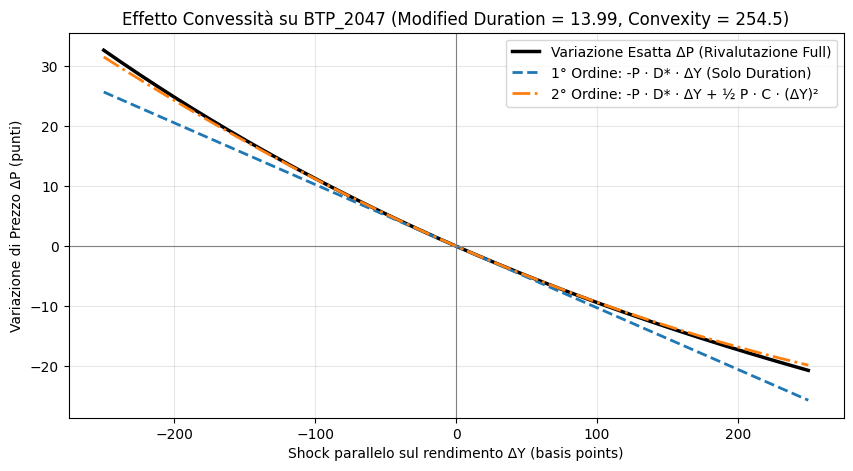

In [ ]:
# Calcolo Macaulay Duration, Modified Duration e Convexity per ciascun BTP
sens_results = []

for i, b in enumerate(btp_specs):
    taus, cfs = get_cashflows(today, b["maturity"], b["coupon"], b["freq"])
    p_mkt = p_today[i]
    ytm = df_pricing.loc[i, "YtM (%)"] / 100.0
    
    # Valori attuali dei singoli flussi scontati allo YtM
    pv_cfs = cfs / (1.0 + ytm)**taus
    
    # Formule delle slide
    mac_dur = np.sum(taus * pv_cfs) / p_mkt
    mod_dur = mac_dur / (1.0 + ytm)
    convexity = np.sum(taus * (taus + 1.0) * pv_cfs) / (p_mkt * (1.0 + ytm)**2)
    
    sens_results.append({
        "BTP": b["name"],
        "Prezzo Mkt": p_mkt,
        "YtM (%)": round(ytm * 100, 3),
        "Macaulay Dur (anni)": round(mac_dur, 3),
        "Modified Dur": round(mod_dur, 3),
        "Convexity": round(convexity, 2),
        # Shock test: variazione esatta vs approssimazioni per +100 bps (+1%)
        "dP Esatto (+1%)": round(np.sum(cfs / (1.0 + ytm + 0.01)**taus) - p_mkt, 3),
        "dP 1° Ord (+1%)": round(-p_mkt * mod_dur * 0.01, 3),
        "dP 2° Ord (+1%)": round(-p_mkt * mod_dur * 0.01 + 0.5 * p_mkt * convexity * (0.01**2), 3),
    })

df_sens = pd.DataFrame(sens_results)
display(df_sens)

# Grafico dell'errore di approssimazione sul titolo più sensibile (BTP_2047)
idx_long = 4  # BTP_2047
taus_L, cfs_L = get_cashflows(today, btp_specs[idx_long]["maturity"], btp_specs[idx_long]["coupon"])
p0_L = p_today[idx_long]
y0_L = df_pricing.loc[idx_long, "YtM (%)"] / 100.0
mod_dur_L = df_sens.loc[idx_long, "Modified Dur"]
conv_L = df_sens.loc[idx_long, "Convexity"]

dy_grid = np.linspace(-0.025, 0.025, 200)  # da -250 bps a +250 bps
dp_exact = np.array([np.sum(cfs_L / (1.0 + y0_L + dy)**taus_L) - p0_L for dy in dy_grid])
dp_1st = -p0_L * mod_dur_L * dy_grid
dp_2nd = -p0_L * mod_dur_L * dy_grid + 0.5 * p0_L * conv_L * (dy_grid**2)

plt.figure(figsize=(10, 5))
plt.plot(dy_grid * 10000, dp_exact, label="Variazione Esatta ΔP (Rivalutazione Full)", linewidth=2.5, color="black")
plt.plot(dy_grid * 10000, dp_1st, "--", label="1° Ordine: -P · D* · ΔY (Solo Duration)", linewidth=2)
plt.plot(dy_grid * 10000, dp_2nd, "-.", label="2° Ordine: -P · D* · ΔY + ½ P · C · (ΔY)²", linewidth=2)
plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(0, color="gray", linewidth=0.8)
plt.title(f"Effetto Convessità su {btp_specs[idx_long]['name']} (Modified Duration = {mod_dur_L:.2f}, Convexity = {conv_L:.1f})")
plt.xlabel("Shock parallelo sul rendimento ΔY (basis points)")
plt.ylabel("Variazione di Prezzo ΔP (punti)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

Serie storica rendimenti completa: 24 giorni (2026-10-20 -> 2026-11-20)


,Nodo (anni),PV Mappato (€),Peso (%),Sensibilità s_k (€)
0,0.25,4677.37,1.07,-1138.35
1,0.50,4060.30,0.93,-1973.05
2,1.00,8441.57,1.93,-8183.05
3,2.00,119003.93,27.15,-229985.80
4,5.00,94222.85,21.50,-453344.51
5,7.00,31636.73,7.22,-212705.20
6,10.00,113786.52,25.96,-1090245.81
7,20.00,62426.76,14.24,-1190857.64


Valore Totale Portafoglio: € 438,256.02
Volatilità giornaliera σ_P: € 1,518.52
VaR 95% (1 giorno):         € 2,497.75 (0.570%)
VaR 99% (1 giorno):         € 3,532.62 (0.806%)


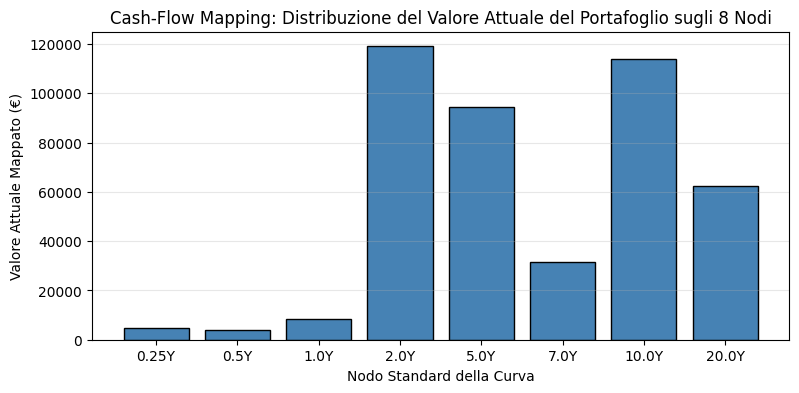

In [ ]:
from scipy.stats import norm

# 1. Recuperiamo tutta la serie storica dei rendimenti (senza il taglio a 24 giorni di df_prices)
df_yields_full = pd.DataFrame({tau: load_csv(fn) / 100.0 for tau, fn in zip(tenors, yield_filenames)}).dropna()
dY_hist = df_yields_full.diff().dropna().to_numpy()   # variazioni giornaliere dei tassi (N_giorni - 1, 8)
Sigma_Y = np.cov(dY_hist, rowvar=False)              # matrice di covarianza 8x8

print(f"Serie storica rendimenti completa: {len(df_yields_full)} giorni ({df_yields_full.index[0].date()} -> {df_yields_full.index[-1].date()})")

# 2. Costruzione del portafoglio: €100.000 di nominale per ciascuno dei 5 BTP
nominal_per_btp = 100_000.0
mapped_pv = np.zeros_like(tenors)  # Vettore M (8 elementi): PV mappato su ciascun nodo

for b in btp_specs:
    taus, cfs = get_cashflows(today, b["maturity"], b["coupon"], b["freq"], face=nominal_per_btp)
    z_spots = svensson(taus, *params_nss)
    pvs = cfs / (1.0 + z_spots)**taus  # Valore attuale di ogni singolo flusso
    
    # Mapping di ogni flusso sui due nodi adiacenti di tenors = [0.25, 0.5, 1, 2, 5, 7, 10, 20]
    for tau_j, pv_j in zip(taus, pvs):
        if tau_j <= tenors[0]:
            mapped_pv[0] += pv_j
        elif tau_j >= tenors[-1]:
            mapped_pv[-1] += pv_j
        else:
            # Trova l'indice k tale che tenors[k] <= tau_j < tenors[k+1]
            k = np.searchsorted(tenors, tau_j) - 1
            alpha = (tau_j - tenors[k]) / (tenors[k + 1] - tenors[k])
            mapped_pv[k] += (1.0 - alpha) * pv_j
            mapped_pv[k + 1] += alpha * pv_j

# 3. Sensibilità monetaria s_k su ciascun nodo e calcolo VaR Parametrico
z_nodes = svensson(tenors, *params_nss)
mod_dur_nodes = tenors / (1.0 + z_nodes)
sens_vector = -mapped_pv * mod_dur_nodes  # vettore s (8 elementi)

portfolio_value = np.sum(mapped_pv)
sigma_P = np.sqrt(sens_vector.T @ Sigma_Y @ sens_vector)

var_95 = norm.ppf(0.95) * sigma_P
var_99 = norm.ppf(0.99) * sigma_P

# Tabella riepilogativa per nodo
df_mapping = pd.DataFrame({
    "Nodo (anni)": tenors,
    "PV Mappato (€)": np.round(mapped_pv, 2),
    "Peso (%)": np.round(mapped_pv / portfolio_value * 100, 2),
    "Sensibilità s_k (€)": np.round(sens_vector, 2)
})
display(df_mapping)

print(f"Valore Totale Portafoglio: € {portfolio_value:,.2f}")
print(f"Volatilità giornaliera σ_P: € {sigma_P:,.2f}")
print(f"VaR 95% (1 giorno):         € {var_95:,.2f} ({var_95/portfolio_value*100:.3f}%)")
print(f"VaR 99% (1 giorno):         € {var_99:,.2f} ({var_99/portfolio_value*100:.3f}%)")

# Grafico dell'esposizione mappata sui 8 nodi
plt.figure(figsize=(9, 4))
plt.bar([str(t) + "Y" for t in tenors], mapped_pv, color="steelblue", edgecolor="black")
plt.title("Cash-Flow Mapping: Distribuzione del Valore Attuale del Portafoglio sugli 8 Nodi")
plt.xlabel("Nodo Standard della Curva")
plt.ylabel("Valore Attuale Mappato (€)")
plt.grid(axis="y", alpha=0.3)
plt.show()